# <center>**Figure 05 : Connectivity Groups, Signal Flow and Layers**</center>

Five example groups (same colors throughout) give a feel for what the groups look like. Everything else is presented in supplementary panels.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("../Scripts"))
from glob import glob

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.patheffects as pe
from matplotlib.collections import LineCollection
from matplotlib.patches import ConnectionPatch
from matplotlib.gridspec import GridSpec
from matplotlib.colors import TwoSlopeNorm, PowerNorm
from matplotlib.lines import Line2D
import seaborn as sns
sns.set_style("ticks")

from scipy.cluster.hierarchy import linkage

import navis
import flybrains

from prats_helpers import place_panel_label
from _compartment_palette import COMP_HEX

home = os.environ["PROJECTS_HOME"]

In [2]:
#------------------------------------------------------------------------------
# Plot params
title_fontsize = 8.5
label_fontsize = 7
tick_fontsize  = 6
cbar_fontsize  = 5
linewidth      = 0.75
scatter_size   = 6
scatter_alpha  = 0.75

# Dendrogram
fisheye_w  = 0.12        # Height of a non-example leaf relative to an example leaf
bg_color   = "#c7c7c7"
bg_width   = 0.2
path_color = "#262626"
path_width = 0.7
ex_width   = 0.9

# Anatomy
neuron_lw      = 0.15
neuron_alpha   = 0.7
neuropil_color = (0.75, 0.75, 0.75, 0.2)
frame_pad      = 1000    # nm around the neuropil
soma_pad       = 3000    # nm around the outermost skeleton node, so the somata are not cut
zoom_out       = 1.0     # Anatomy frames in A and B, relative to the tight frame
psd_color      = "#41ab5d"
psd_alpha      = 0.15
tbar_color     = "#e31a1c"
tbar_alpha     = 0.4
site_size      = 0.3
site_grey      = "#9e9e9e"   # Sites behind the vector
arrow_edge     = 0.4         # Black outline around the vector

# Bars
bar_height   = 0.22
ipsi_color   = "#bdbdbd"
contra_color = "#6a3d9a"
contra_alpha = 0.4       # Contralateral segments are a lighter tint of the compartment color

# Mixture distance
mixture_thr  = 0.05      # Groups closer than this to the global mixture are grey
mixture_grey = "#bdbdbd"

# Panel Labels
label_kwargs = dict(fontsize = 16, va = "top", ha = "left")

### Example groups

In dendrogram order. g058 and g059 are sister groups, g056 sits at the sensory end (AL), g108 is the LAL commissural group, g213 descends into the SEZ / VNC.

In [3]:
examples = ["g056", "g058", "g059", "g108", "g213"]

# From the working palette -- away from tab10 (roles, modalities) and the compartment colors
example_colors = {"g056" : "#000075",
                  "g058" : "#469990",
                  "g059" : "#f032e6",
                  "g108" : "#42d4f4",
                  "g213" : "#9A6324"}

#------------------------------------------------------------------------------
# Roles -- same as embed_signal_flow.py
role_order = ["Sensory_Broadcast",
              "Focused_Relay",
              "Broad_Relay",
              "Focused_Convergence",
              "Broad_Convergence",
              "Recurrent_Processor",
              "Signal_Sink"]
role_cmap  = dict(zip(role_order, sns.color_palette("tab10", len(role_order))))

#------------------------------------------------------------------------------
# Modalities -- same as embed_signal_integration.py
modalities     = ["Olf", "Gust", "Vis", "Thermo"]
modality_names = {"Olf"    : "Olfactory",
                  "Gust"   : "Gustatory",
                  "Vis"    : "Visual",
                  "Thermo" : "Thermosensory"}
modality_cmap  = dict(zip(modalities, sns.color_palette("tab10", len(modalities))))

#------------------------------------------------------------------------------
# Level1 compartments -- names not in the palette get the closest color
comp_order = ["AL", "TR", "LON",
              "MB-CA", "MB-ACA", "MB-sansCA",
              "SMP",
              "IPA", "IPLM", "IPP",
              "SLP",
              "LAL", "VMC",
              "VLP",
              "SEZneu", "VNCneu"]

comp_colors = {c : COMP_HEX[c] for c in comp_order if c in COMP_HEX}
comp_colors["MB-sansCA"] = COMP_HEX["MB"]
comp_colors["MB-ACA"]    = "#4292c6"
comp_colors["SEZneu"]    = COMP_HEX["SEZ-VNC"]
comp_colors["VNCneu"]    = "#95a5a6"

### Load data

- `ClusteredMatrix_Central_128_8` : 8 SVD dimensions of the hemisphere-averaged ASE (central classes), in dendrogram leaf order
- `Groups_Separated_128_8_Corrected` : Class -> Group
- `Synapse-by-Neuron_level1` : PSDs and T-bars of every neuron per level1 compartment (`L1_Neuron-Typing`, read-only)
- `Group_Dendrite-to-Axon_Distance` : dendritic PSD / axonal T-bar centroids, projection length and `dz` (symmetrized, um)
- `Group_Positions` : whole-neuron centroid of every group (symmetrized, nm)
- `Group_Functional-Roles`, `Signal-Integration_Group_Layers-Assignment_k-10` : roles, layers, drive, depth
- `Layer_Connectivity-Matrix` : layer x hemisphere connectivity
- `Source_Groups` : the sensory-entry groups

In [4]:
#------------------------------------------------------------------------------
# Embedding + groups
embedding = pd.read_parquet("../Analysis_Outputs/Embedding/ClusteredMatrix_Central_128_8.parquet")
groups    = pd.read_csv("../Analysis_Outputs/Embedding/Groups_Separated_128_8_Corrected.csv")
groups["Group"] = groups["Group"].apply(lambda g : f"g{g:03d}")

#------------------------------------------------------------------------------
# Neurons + synapses
neuron_df  = pd.read_csv(f"{home}/L1_Skeletons/Data_Summary/L1_NeuronInformation_PK.csv")
neuron_df  = neuron_df.loc[neuron_df["Category"] == "Diff"]
synapse_df = pd.read_parquet(f"{home}/L1_Neuron-Typing/Analysis_Outputs/Synapses/Synapse-by-Neuron_level1.parquet")

#------------------------------------------------------------------------------
# Anatomy
dist      = pd.read_parquet("../Analysis_Outputs/Group_Anatomy/Group_Dendrite-to-Axon_Distance.parquet")
positions = pd.read_parquet("../Analysis_Outputs/Group_Anatomy/Group_Positions.parquet")

#------------------------------------------------------------------------------
# Signal flow + layers
roles         = pd.read_parquet("../Analysis_Outputs/Group_Signal-Flow/Group_Functional-Roles.parquet")
layer_df      = pd.read_parquet("../Analysis_Outputs/Group_Layer-Network/Signal-Integration_Group_Layers-Assignment_k-10.parquet")
layer_mat     = pd.read_parquet("../Analysis_Outputs/Group_Layer-Network/Layer_Connectivity-Matrix.parquet")
source_groups = np.load("../Analysis_Outputs/Group_Layer-Network/Source_Groups.npy", allow_pickle = True)

#------------------------------------------------------------------------------
# Right hemisphere only, indexed by group
dist      = dist.loc[dist["Hemisphere"] == "Right"].set_index("Group")
positions = positions.loc[(positions["Fragment"]   == "Neuron") &
                          (positions["Hemisphere"] == "Right")].set_index("Group")
roles     = roles.set_index("Group")
layer_df  = layer_df.set_index("Group")

### Hierarchy

Ward linkage on the 8 SVD dimensions -- same as `generate_hierarchy` in `embed.py` -- with the heights sqrt compressed as in `compress_linkage`. The saved matrix is already in leaf order, which is checked.

In [5]:
# Map every class to its group
group_dict   = dict(zip(groups["Class"], groups["Group"]))
class_groups = embedding.index.map(group_dict).to_numpy()

# Linkage
X = embedding.iloc[:, :8].to_numpy()
N = X.shape[0]
Z = linkage(X,
            method = "ward",
            metric = "euclidean")

# Sqrt compression -- same as compress_linkage in embed.py
heights = np.sqrt(Z[:, 2])

# Leaves under every node (leaves are 0 .. N-1, merges are N .. 2N-2)
leaves = {i : [i] for i in range(N)}
for i in range(N - 1):
    left  = int(Z[i, 0])
    right = int(Z[i, 1])
    leaves[N + i] = leaves[left] + leaves[right]

# The saved matrix is already in leaf order
assert leaves[2 * N - 2] == list(range(N))

print(f"{N} classes | {len(set(class_groups))} central groups | {groups['Group'].nunique()} groups total")

586 classes | 215 central groups | 233 groups total


### Fisheye layout

Every branch is kept, in the same leaf order as the clustermap in `embed.py` (drawn top to bottom). Leaves of the example groups get the full vertical spacing, every other leaf gets `fisheye_w` of it. Links are drawn in three styles :
- inside an example group : example color
- on the path from the root to an example : dark
- everything else : light grey

In [6]:
is_example = np.isin(class_groups, examples)

# Leaf positions -- example leaves get the full height
leaf_height = np.where(is_example, 1.0, fisheye_w)
leaf_y      = np.cumsum(leaf_height) - leaf_height / 2

# Node positions -- x is the merge height, y the middle of the two children
xpos = {i : 0.0       for i in range(N)}
ypos = {i : leaf_y[i] for i in range(N)}

for i in range(N - 1):
    left  = int(Z[i, 0])
    right = int(Z[i, 1])
    xpos[N + i] = heights[i]
    ypos[N + i] = (ypos[left] + ypos[right]) / 2

#------------------------------------------------------------------------------
def node_style(node):
    """
    Kind, color and width of the link above a node.
    """
    node_groups = np.unique(class_groups[leaves[node]])

    # Inside one example group
    if len(node_groups) == 1 and node_groups[0] in examples:
        return "example", example_colors[node_groups[0]], ex_width

    # On the way to an example
    if is_example[leaves[node]].any():
        return "path", path_color, path_width

    return "background", bg_color, bg_width

#------------------------------------------------------------------------------
# Links, kept apart by kind so they can be drawn background first
links = {"background" : [],
         "path"       : [],
         "example"    : []}

for i in range(N - 1):
    node  = N + i
    left  = int(Z[i, 0])
    right = int(Z[i, 1])

    # Vertical link at the merge
    kind, color, width = node_style(node)
    segment = [(xpos[node], ypos[left]), (xpos[node], ypos[right])]
    links[kind].append((segment, color, width))

    # Horizontal link to each child
    for child in [left, right]:
        kind, color, width = node_style(child)
        segment = [(xpos[child], ypos[child]), (xpos[node], ypos[child])]
        links[kind].append((segment, color, width))

#------------------------------------------------------------------------------
# Where the sister groups (g058, g059) split -- the first merge that contains both
sister_leaves = set(np.where(np.isin(class_groups, ["g058", "g059"]))[0])

for i in range(N - 1):
    if sister_leaves <= set(leaves[N + i]):
        sister_split = N + i
        break

### Synapse location

For each group's right hemisphere neurons : fraction of PSDs (In) and T-bars (Out) in each level1 compartment, split into the ipsilateral (right) and contralateral (left) side. In the bars the ipsilateral compartments come first (solid), then the contralateral ones (light), so the contralateral share is everything right of the black tick.

In [7]:
synapse_df["Comp"] = synapse_df["Compartment"].str.rsplit("_", n = 1).str[0]
synapse_df["Side"] = synapse_df["Compartment"].str.rsplit("_", n = 1).str[1]

#------------------------------------------------------------------------------
def right_neurons(group):
    return neuron_df.loc[(neuron_df["ConnectivityGroup"] == group) &
                         (neuron_df["Hemisphere"]        == "Right"), "bodyId"]

def synapse_fractions(group, connector):
    """
    Fraction of a group's PSDs or T-bars in every compartment, per side.
    Right hemisphere neurons, so Right = ipsilateral and Left = contralateral.
    """
    sub = synapse_df.loc[(synapse_df["bodyId"].isin(right_neurons(group))) &
                         (synapse_df["Connector"] == connector)]

    frac = sub.pivot_table(index      = "Side",
                           columns    = "Comp",
                           values     = "Count",
                           aggfunc    = "sum",
                           fill_value = 0)
    frac = frac / frac.to_numpy().sum()

    return frac.reindex(index      = ["Right", "Left"],
                        columns    = comp_order,
                        fill_value = 0)

#------------------------------------------------------------------------------
synapse_frac = {}
for g in examples:
    synapse_frac[g] = {"In"  : synapse_fractions(g, "PSDs"),
                       "Out" : synapse_fractions(g, "TBars")}

    contra_in  = synapse_frac[g]["In"].loc["Left"].sum()
    contra_out = synapse_frac[g]["Out"].loc["Left"].sum()
    print(f"{g} : contralateral In {contra_in:.2f} | contralateral Out {contra_out:.2f}")

#------------------------------------------------------------------------------
# Compartments with at least 2% in any bar (both sides together)
used_comps = []
for c in comp_order:
    largest = max(synapse_frac[g][k][c].sum() for g in examples for k in ["In", "Out"])
    if largest >= 0.02:
        used_comps.append(c)

g056 : contralateral In 0.00 | contralateral Out 0.00
g058 : contralateral In 0.04 | contralateral Out 0.21
g059 : contralateral In 0.05 | contralateral Out 0.27
g108 : contralateral In 0.26 | contralateral Out 0.84
g213 : contralateral In 0.00 | contralateral Out 0.00


### Example skeletons

Right hemisphere skeletons with their connectors (type 1 = PSD, type 0 = T-bar), symmetrized. Split into axon and dendrite exactly as in `embed_group_positions.py` (`synapse_flow_centrality`), keeping the PSDs of the dendrites and the T-bars of the axons -- the same sites that the dendrite -> axon centroids are computed from.

In [8]:
skeleton_paths = glob(f"{home}/L1_Skeletons/Skeletons/Diff_Skeletons/*/Right/*.swc")
skeleton_dict  = {os.path.basename(p)[:-4] : p for p in skeleton_paths}

skeletons      = {}
dendritic_psds = {}
axonal_tbars   = {}

for g in examples:
    # Read + symmetrize
    paths = [skeleton_dict[str(b)] for b in right_neurons(g) if str(b) in skeleton_dict]
    neus  = navis.read_swc(paths,
                           fmt              = "{id}.swc",
                           connector_labels = {0 : 7, 1 : 8})
    neus  = navis.xform_brain(neus,
                              source = "PK_L1CNS",
                              target = "PK_L1CNSsym")
    neus  = neus[pd.Series(neus.n_connectors).fillna(0) > 0]

    # Split
    pieces    = navis.split_axon_dendrite(neus, metric = "synapse_flow_centrality")
    dendrites = pieces[pieces.compartment == "dendrite"]
    axons     = pieces[pieces.compartment == "axon"]

    # PSDs of the dendrites, T-bars of the axons
    psds = pd.concat([n.connectors for n in dendrites if n.connectors is not None])
    tbar = pd.concat([n.connectors for n in axons     if n.connectors is not None])

    skeletons[g]      = neus
    dendritic_psds[g] = psds.loc[psds["type"] == 1]
    axonal_tbars[g]   = tbar.loc[tbar["type"] == 0]

    print(f"{g} : {len(neus)} neurons | "
          f"{len(dendritic_psds[g])} dendritic PSDs | "
          f"{len(axonal_tbars[g])} axonal T-bars | "
          f"{dist.loc[g, 'distance']:.1f} um")

Importing:   0%|          | 0/10 [00:00<?, ?it/s]

Transform path: PK_L1CNS -> PK_L1CNSsym


Xforming:   0%|          | 0/10 [00:00<?, ?it/s]

Splitting:   0%|          | 0/10 [00:00<?, ?it/s]

/home/prat/anaconda3/envs/prat_connectome/lib/python3.11/site-packages/numpy/lib/arraysetops.py:717: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison
  mask |= (ar1 == a)
/home/prat/anaconda3/envs/prat_connectome/lib/python3.11/site-packages/numpy/lib/arraysetops.py:717: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison
  mask |= (ar1 == a)
/home/prat/anaconda3/envs/prat_connectome/lib/python3.11/site-packages/numpy/lib/arraysetops.py:717: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison
  mask |= (ar1 == a)
/home/prat/anaconda3/envs/prat_connectome/lib/python3.11/site-packages/numpy/lib/arraysetops.py:717: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison
  mask |= (ar1 == a)
/home/pr

g056 : 10 neurons | 3534 dendritic PSDs | 889 axonal T-bars | 1.1 um


... (22 outputs left out)

Splitting:   0%|          | 0/3 [00:00<?, ?it/s]

/home/prat/anaconda3/envs/prat_connectome/lib/python3.11/site-packages/numpy/lib/arraysetops.py:717: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison
  mask |= (ar1 == a)
/home/prat/anaconda3/envs/prat_connectome/lib/python3.11/site-packages/numpy/lib/arraysetops.py:717: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison
  mask |= (ar1 == a)


g213 : 3 neurons | 173 dendritic PSDs | 101 axonal T-bars | 53.3 um


/home/prat/anaconda3/envs/prat_connectome/lib/python3.11/site-packages/numpy/lib/arraysetops.py:717: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison
  mask |= (ar1 == a)


### Brain volume

Symmetrized central brain neuropil, `dz` colormap and arrow widths -- all as in `embed_group_positions.py`. The anatomy panels in A and B use the full neuropil, extended to every node of the example skeletons -- the somata sit in the cortex outside the neuropil, and g213 descends into the VNC.

In [9]:
neuropil = navis.Volume(flybrains.PK_L1CBNeuropilsym.mesh)
neuropil.color = neuropil_color

#------------------------------------------------------------------------------
# NOTE : the mesh has one stray vertex at (-727, 1743, 13) -- leave it out of the frame
vertices   = neuropil.vertices[neuropil.vertices[:, 0] > 0]
brain_xlim = (vertices[:, 0].min() - frame_pad, vertices[:, 0].max() + frame_pad)
brain_ylim = (vertices[:, 1].max() + frame_pad, vertices[:, 1].min() - frame_pad)

#------------------------------------------------------------------------------
# Anatomy panels -- extended to every node of the example skeletons (somata, VNC)
nodes = pd.concat([n.nodes for g in examples for n in skeletons[g]])

anatomy_xlim = (min(brain_xlim[0], nodes["x"].min() - soma_pad),
                max(brain_xlim[1], nodes["x"].max() + soma_pad))
anatomy_ylim = (max(brain_ylim[0], nodes["y"].max() + soma_pad),
                min(brain_ylim[1], nodes["y"].min() - soma_pad))

# Zoom out a little, around the centre of the frame
def zoom(lims, factor):
    centre = (lims[0] + lims[1]) / 2
    half   = (lims[1] - lims[0]) / 2 * factor
    return (centre - half, centre + half)

anatomy_xlim = zoom(anatomy_xlim, zoom_out)
anatomy_ylim = zoom(anatomy_ylim, zoom_out)

#------------------------------------------------------------------------------
# Anteroposterior direction -- same colormap as embed_group_positions.py, fixed at +-25 um
dz_lim  = 25
dz_norm = TwoSlopeNorm(vmin    = -dz_lim,
                       vcenter = 0,
                       vmax    = dz_lim)
dz_cmap = cm.ScalarMappable(norm = dz_norm, cmap = "vlag")

#------------------------------------------------------------------------------
# Arrow width from group size -- same as embed_group_positions.py
smin = dist["Size"].min()
smax = dist["Size"].max()

def size2lw(s):
    f = (np.sqrt(s) - np.sqrt(smin)) / (np.sqrt(smax) - np.sqrt(smin))
    return 0.3 + f * 2.0

### Distance from the global sensory mixture

Same baseline as the modality enrichment in `embed_signal_integration.py` : the mean proportion of each modality's drive (`*_Mean_Drive`) across all non-sensory groups. A fully integrated group should carry this global mixture -- mostly gustatory, because most of the peripheral input is gustatory -- rather than an equal split.

For every group, the total variation distance between its own mixture p and the global mixture b, 0.5 * sum |p - b| : 0 = exactly the global mixture, 1 = completely different. Groups are colored by the modality they are most enriched in (largest p - b); groups within `mixture_thr` of the global mixture are grey, as their deviation is too small for the color to mean anything.

In [10]:
# Mixture of every group
drive = layer_df[[f"{m}_Mean_Drive" for m in modalities]].to_numpy()
drive = drive / drive.sum(axis = 1, keepdims = True)

# Global mixture -- mean over the non-sensory groups, as for the enrichment
is_sensory = layer_df.index.isin(source_groups)
baseline   = drive[~is_sensory].mean(axis = 0)

# Sanity check -- same baseline as the stored enrichment
enrichment = layer_df[[f"{m}_Enrichment" for m in modalities]].to_numpy()
assert np.allclose((drive - baseline) / baseline, enrichment)

#------------------------------------------------------------------------------
# Distance + most enriched modality
deviation = drive - baseline
layer_df["Mixture_Distance"]  = 0.5 * np.abs(deviation).sum(axis = 1)
layer_df["Enriched_Modality"] = np.array(modalities)[deviation.argmax(axis = 1)]

# Grey when too close to the global mixture
layer_df["Mixture_Color"] = [modality_cmap[m] for m in layer_df["Enriched_Modality"]]
layer_df.loc[layer_df["Mixture_Distance"] < mixture_thr, "Mixture_Color"] = mixture_grey

#------------------------------------------------------------------------------
shallow = layer_df.loc[layer_df["Final_Score"] < 0.15, "Mixture_Distance"].median()
deep    = layer_df.loc[layer_df["Final_Score"] > 0.25, "Mixture_Distance"].median()

print("Global mixture :", dict(zip(modalities, baseline.round(3))))
print(f"Median distance, depth < 0.15 : {shallow:.2f}")
print(f"Median distance, depth > 0.25 : {deep:.2f}")

Global mixture : {'Olf': 0.372, 'Gust': 0.505, 'Vis': 0.073, 'Thermo': 0.05}
Median distance, depth < 0.15 : 0.49
Median distance, depth > 0.25 : 0.05


### Ipsi vs contralateral layer connectivity

Every cell is a fraction of **all** synapses in the brain. The two hemispheres are pooled :

- Ipsi   (l -> k) = (Left_l -> Left_k  + Right_l -> Right_k) / all synapses
- Contra (l -> k) = (Left_l -> Right_k + Right_l -> Left_k)  / all synapses

Pooling is the same as averaging the two hemispheres over the averaged total, (L + R) / 2 / ((L_total + R_total) / 2), so every synapse counts once with the same weight. Both blocks together sum to 1, and the bars are their row sums (also summing to 1).

In [11]:
total_syn  = layer_mat.to_numpy().sum()
ipsi_mat   = np.zeros((11, 11))
contra_mat = np.zeros((11, 11))

for hemi, other in [("Left", "Right"), ("Right", "Left")]:
    ipsi_cols   = [f"{hemi}_{k:02d}"  for k in range(11)]
    contra_cols = [f"{other}_{k:02d}" for k in range(11)]

    for l in range(11):
        row = layer_mat.loc[f"{hemi}_{l:02d}"]
        ipsi_mat[l]   += row[ipsi_cols].to_numpy()
        contra_mat[l] += row[contra_cols].to_numpy()

# Fractions of all synapses
ipsi_mat   = ipsi_mat   / total_syn
contra_mat = contra_mat / total_syn
assert np.isclose(ipsi_mat.sum() + contra_mat.sum(), 1)

#------------------------------------------------------------------------------
# Row sums -- each layer's ipsi and contra output as a fraction of all synapses
ipsi_rows   = ipsi_mat.sum(axis = 1)
contra_rows = contra_mat.sum(axis = 1)

# Groups per layer
groups_per_layer = layer_df["Layer"].value_counts().reindex(range(11), fill_value = 0)

#------------------------------------------------------------------------------
contra_total = contra_mat.sum()
contra_mid   = contra_rows[3:7].sum() / contra_rows.sum()
print(f"Contra : {contra_total:.1%} of all synapses | L3-L6 : {contra_mid:.0%} of them")

pd.DataFrame({"Ipsi"   : ipsi_rows,
              "Contra" : contra_rows,
              "Groups" : groups_per_layer}).round(3).T

Contra : 28.3% of all synapses | L3-L6 : 78% of them


Layer,0,1,2,3,4,5,6,7,8,9,10
Ipsi,0.083,0.046,0.040,0.110,0.154,0.088,0.103,0.043,0.030,0.016,0.005
Contra,0.006,0.001,0.009,0.049,0.065,0.047,0.060,0.021,0.017,0.007,0.001
Groups,18.000,3.000,7.000,16.000,27.000,33.000,46.000,27.000,32.000,17.000,7.000


### Plot helpers

In [12]:
def style_axis(a):
    sns.despine(ax = a)
    a.tick_params(
        axis      = "both",
        which     = "major",
        color     = "black",
        labelsize = tick_fontsize,
        length    = 2,
        width     = 0.75,
        pad       = 1.5)


def draw_neuropil(a):
    navis.plot2d(neuropil,
                 method    = "2d",
                 view      = ("x", "-y"),
                 ax        = a,
                 rasterize = True)


def anatomy_frame(a, xlim, ylim):
    """
    Fixed frame, no ticks.
    """
    a.set_xlim(*xlim)
    a.set_ylim(*ylim)
    a.set_aspect("equal")
    a.axis("off")


def dot(color, size = 3):
    """
    Round legend handle.
    """
    return Line2D([], [],
                  ls     = "",
                  marker = "o",
                  ms     = size,
                  color  = color)


def box(color, alpha = 1):
    """
    Square legend handle.
    """
    return plt.Rectangle((0, 0), 1, 1,
                         color = color,
                         alpha = alpha)

## Main Figure

Plot neurons:   0%|          | 0/33 [00:00<?, ?it/s]

Plot neurons:   0%|          | 0/19 [00:00<?, ?it/s]

Plot neurons:   0%|          | 0/17 [00:00<?, ?it/s]

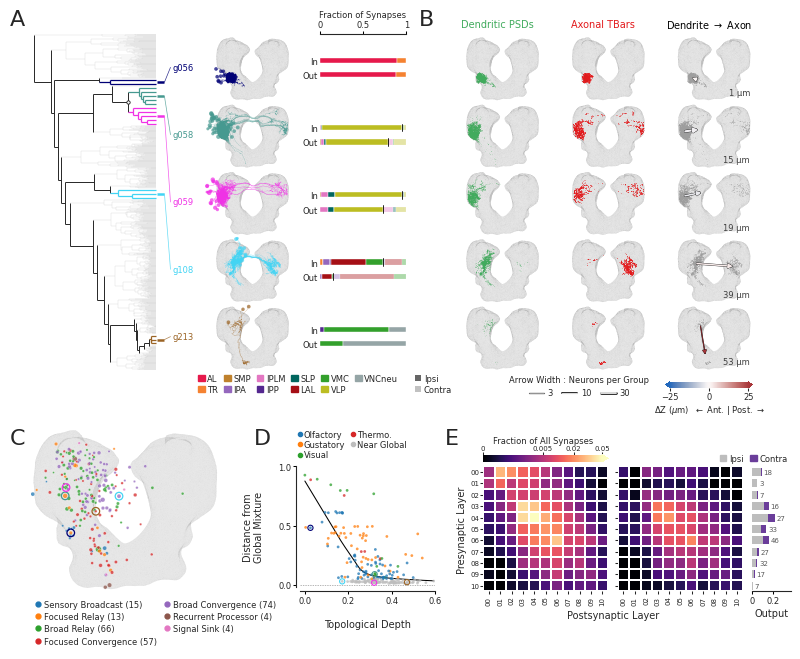

In [13]:
# Letter page -- the panels fill the top, the bottom of the page is left open
page_w, page_h = 8.5, 11
margin         = 0.5                                 # inch
n_rows, n_cols = 66, 78
cell           = (page_w - 2 * margin) / n_cols      # square cells

fig  = plt.figure(figsize = (page_w, page_h))
grid = GridSpec(n_rows, n_cols,
                figure = fig,
                left   = margin / page_w,
                right  = 1 - margin / page_w,
                top    = 1 - margin / page_h,
                bottom = 1 - (margin + n_rows * cell) / page_h,
                hspace = 0,
                wspace = 0)

# A + B -- one header row, then a block of rows for every example
ex_rows = 7
ex_top  = 2
ab_end  = ex_top + len(examples) * ex_rows

def example_rows(r):
    return slice(ex_top + r * ex_rows, ex_top + (r + 1) * ex_rows)

# A + B -- columns
cols = {"dendrogram" : slice(0, 14),
        "label"      : slice(14, 17),
        "morphology" : slice(17, 28),
        "bars"       : slice(30, 39),
        "psds"       : slice(43, 54),
        "tbars"      : slice(54, 65),
        "vector"     : slice(65, 76)}

def column_title(column, text, color = "black"):
    a = fig.add_subplot(grid[0:2, cols[column]])
    a.axis("off")
    a.text(0.5, 0.5, text,
           transform = a.transAxes,
           ha        = "center",
           va        = "center",
           fontsize  = label_fontsize,
           color     = color)

#-----------------------------------------------------------------------------
# A -- Dendrogram
ax_dend = fig.add_subplot(grid[ex_top:ab_end, cols["dendrogram"]])

for kind in ["background", "path", "example"]:
    segments = [segment for segment, _, _ in links[kind]]
    colors   = [color   for _, color, _   in links[kind]]
    widths   = [width   for _, _, width   in links[kind]]

    ax_dend.add_collection(LineCollection(segments,
                                          colors     = colors,
                                          linewidths = widths,
                                          capstyle   = "butt"))

ax_dend.set_xlim(heights.max() * 1.02, -0.35)
ax_dend.set_ylim(leaf_y[-1] + leaf_height[-1] / 2, 0)
ax_dend.axis("off")

# Sister split
ax_dend.plot(xpos[sister_split], ypos[sister_split],
             marker = "o",
             ms     = 2.4,
             mfc    = "white",
             mec    = "0.1",
             mew    = 0.6,
             zorder = 5)

# Column titles
column_title("psds",       "Dendritic PSDs", psd_color)
column_title("tbars",      "Axonal TBars",   tbar_color)
column_title("vector",     r"Dendrite $\rightarrow$ Axon")

#-----------------------------------------------------------------------------
# One row per example
for r, g in enumerate(examples):
    color = example_colors[g]
    row   = dist.loc[g]
    leaf  = leaf_y[class_groups == g].mean()

    #-------------------------------------------------------------------------
    # A -- Group label, where the dendrogram connector lands
    ax_label = fig.add_subplot(grid[example_rows(r), cols["label"]])
    ax_label.axis("off")
    ax_label.text(0.22, 0.5, g,
                  transform  = ax_label.transAxes,
                  ha         = "left",
                  va         = "center",
                  fontsize   = tick_fontsize,
                  color      = color)

    # Leaf tick + connector
    ax_dend.plot([-0.02, -0.30], [leaf, leaf],
                 color          = color,
                 lw             = 1.8,
                 solid_capstyle = "butt")
    fig.add_artist(ConnectionPatch(xyA     = (-0.30, leaf),
                                   coordsA = ax_dend.transData,
                                   xyB     = (0.16, 0.5),
                                   coordsB = ax_label.transAxes,
                                   color   = color,
                                   lw      = 0.5,
                                   alpha   = 0.8))

    #-------------------------------------------------------------------------
    # A -- Morphology
    ax_morph = fig.add_subplot(grid[example_rows(r), cols["morphology"]])
    draw_neuropil(ax_morph)
    navis.plot2d(skeletons[g],
                 method     = "2d",
                 view       = ("x", "-y"),
                 color      = color,
                 radius     = False,
                 soma       = True,
                 connectors = False,
                 linewidth  = neuron_lw,
                 alpha      = neuron_alpha,
                 ax         = ax_morph,
                 rasterize  = True)
    anatomy_frame(ax_morph, anatomy_xlim, anatomy_ylim)

    #-------------------------------------------------------------------------
    # A -- Synapse location : ipsi compartments (solid), then contra compartments (light)
    ax_bars = fig.add_subplot(grid[example_rows(r), cols["bars"]])

    for y, key in [(0, "In"), (0.6, "Out")]:
        frac = synapse_frac[g][key]
        left = 0

        # Ipsi
        for c in comp_order:
            if frac.loc["Right", c] > 0:
                ax_bars.barh(y, frac.loc["Right", c],
                             left      = left,
                             height    = bar_height,
                             color     = comp_colors[c],
                             edgecolor = "white",
                             linewidth = 0.3)
                left += frac.loc["Right", c]

        # Ipsi | contra boundary
        if 0 < left < 1:
            ax_bars.plot([left, left], [y - bar_height * 0.75, y + bar_height * 0.75],
                         color = "black",
                         lw    = 0.6)

        # Contra
        for c in comp_order:
            if frac.loc["Left", c] > 0:
                ax_bars.barh(y, frac.loc["Left", c],
                             left      = left,
                             height    = bar_height,
                             color     = comp_colors[c],
                             alpha     = contra_alpha,
                             edgecolor = "white",
                             linewidth = 0.3)
                left += frac.loc["Left", c]

    ax_bars.set_xlim(0, 1)
    ax_bars.set_ylim(1.7, -1.1)
    ax_bars.set_yticks([0, 0.6])
    ax_bars.set_yticklabels(["In", "Out"], fontsize = tick_fontsize)
    ax_bars.set_xticks([0, 0.5, 1])
    style_axis(ax_bars)
    ax_bars.tick_params(axis = "y", length = 0)

    # Only the first row keeps its x-axis, on top
    if r > 0:
        ax_bars.set_xticklabels([])
        ax_bars.tick_params(axis = "x", length = 0)
        sns.despine(ax = ax_bars, left = True, bottom = True)
    else:
        ax_bars.xaxis.tick_top()
        ax_bars.xaxis.set_label_position("top")
        ax_bars.set_xticklabels(["0", "0.5", "1"], fontsize = tick_fontsize)
        ax_bars.set_xlabel("Fraction of Synapses", fontsize = tick_fontsize, labelpad = 2)
        sns.despine(ax = ax_bars, left = True, bottom = True, top = False)
        ax_bars.tick_params(axis = "x", top = True, bottom = False)   # despine hides the top ticks after tick_top()

    #-------------------------------------------------------------------------
    # B -- Dendritic PSDs
    ax_psd = fig.add_subplot(grid[example_rows(r), cols["psds"]])
    draw_neuropil(ax_psd)
    ax_psd.scatter(dendritic_psds[g]["x"], dendritic_psds[g]["y"],
                   s          = site_size,
                   color      = psd_color,
                   alpha      = psd_alpha,
                   lw         = 0,
                   zorder     = 3,
                   rasterized = True)
    anatomy_frame(ax_psd, anatomy_xlim, anatomy_ylim)

    #-------------------------------------------------------------------------
    # B -- Axonal TBars
    ax_tbar = fig.add_subplot(grid[example_rows(r), cols["tbars"]])
    draw_neuropil(ax_tbar)
    ax_tbar.scatter(axonal_tbars[g]["x"], axonal_tbars[g]["y"],
                    s          = site_size,
                    color      = tbar_color,
                    alpha      = tbar_alpha,
                    lw         = 0,
                    zorder     = 3,
                    rasterized = True)
    anatomy_frame(ax_tbar, anatomy_xlim, anatomy_ylim)

    #-------------------------------------------------------------------------
    # B -- Dendrite -> axon vector, over all sites in grey
    ax_vec = fig.add_subplot(grid[example_rows(r), cols["vector"]])
    draw_neuropil(ax_vec)

    sites = pd.concat([dendritic_psds[g], axonal_tbars[g]])
    ax_vec.scatter(sites["x"], sites["y"],
                   s          = site_size,
                   color      = site_grey,
                   alpha      = psd_alpha,
                   lw         = 0,
                   zorder     = 2,
                   rasterized = True)

    arrow_lw = size2lw(row["Size"])
    ax_vec.annotate("",
                    xytext = (row["Pos_x_dend"] * 1000, row["Pos_y_dend"] * 1000),
                    xy     = (row["Pos_x_axon"] * 1000, row["Pos_y_axon"] * 1000),
                    arrowprops = dict(arrowstyle     = "-|>",
                                      color          = dz_cmap.to_rgba(row["dz"]),
                                      lw             = arrow_lw,
                                      alpha          = 1,
                                      shrinkA        = 0,
                                      shrinkB        = 0,
                                      mutation_scale = 6,
                                      path_effects   = [pe.withStroke(linewidth  = arrow_lw + arrow_edge,
                                                                      foreground = "black")]),
                    zorder = 5)
    anatomy_frame(ax_vec, anatomy_xlim, anatomy_ylim)

    # Projection length, in the empty corner under the lobe
    ax_vec.text(0.97, 0.06, f"{row['distance']:.0f} µm",
                transform = ax_vec.transAxes,
                ha        = "right",
                va        = "bottom",
                fontsize  = tick_fontsize,
                color     = "0.25")

#-----------------------------------------------------------------------------
# A -- Compartment legend under the morphology and the bars, then Ipsi | Contra after a gap
ax_leg = fig.add_subplot(grid[ab_end : ab_end + 3, 17:42])
ax_leg.axis("off")

comp_handles = [box(comp_colors[c]) for c in used_comps]
side_handles = [box("0.4"), box("0.4", alpha = contra_alpha)]
for h in side_handles:
    h.set_linewidth(0)

legend_kwargs = dict(fontsize      = tick_fontsize,
                     frameon       = False,
                     handlelength  = 0.8,
                     handleheight  = 0.8,
                     handletextpad = 0.3,
                     columnspacing = 0.7,
                     labelspacing  = 0.3,
                     borderaxespad = 0)

comp_legend = ax_leg.legend(comp_handles, used_comps,
                            loc  = "upper left",
                            ncol = 6,
                            **legend_kwargs)
ax_leg.add_artist(comp_legend)

# Ipsi | Contra start a little after the last compartment column
fig.canvas.draw()
comp_box = comp_legend.get_window_extent().transformed(ax_leg.transAxes.inverted())
ax_leg.legend(side_handles, ["Ipsi", "Contra"],
              loc            = "upper left",
              bbox_to_anchor = (comp_box.x1 + 0.04, 1),
              **legend_kwargs)

#-----------------------------------------------------------------------------
# B -- Arrow width = group size
ax_size = fig.add_subplot(grid[ab_end : ab_end + 3, 49:65])
ax_size.axis("off")
size_handles = [Line2D([], [],
                       color        = "0.85",
                       lw           = size2lw(s),
                       path_effects = [pe.withStroke(linewidth  = size2lw(s) + arrow_edge,
                                                     foreground = "black")])
                for s in [3, 10, 30]]
ax_size.legend(size_handles, ["3", "10", "30"],
               title          = "Arrow Width : Neurons per Group",
               title_fontsize = tick_fontsize,
               loc            = "upper center",
               ncol           = 3,
               fontsize       = tick_fontsize,
               frameon        = False,
               handlelength   = 1.8,
               handletextpad  = 0.4,
               columnspacing  = 1.2,
               borderaxespad  = 0.2)

#-----------------------------------------------------------------------------
# B -- Colorbar for the anteroposterior direction, under the vectors
ax_dz = fig.add_subplot(grid[ab_end + 1, slice(cols["vector"].start + 1, cols["vector"].stop - 1)])
ax_dz.axis("off")

cax  = ax_dz.inset_axes([0, 0.2, 1, 0.6])
cbar = fig.colorbar(dz_cmap,
                    cax         = cax,
                    orientation = "horizontal",
                    extend      = "both",
                    ticks       = [-dz_lim, 0, dz_lim])
cbar.ax.tick_params(labelsize = tick_fontsize,
                    length    = 2,
                    width     = 0.75,
                    pad       = 1)
cbar.outline.set_visible(False)
cbar.set_label(r"$\Delta$Z ($\mu$m)  " +
               r"$\leftarrow$ Ant. | Post. $\rightarrow$",
               fontsize = tick_fontsize,
               labelpad = 1.5)

#-----------------------------------------------------------------------------
# Bottom row -- every panel shares the same bottom
bottom_top = 43                 # panel labels, the key of D and the colorbar of E
panel_rows = slice(47, 60)      # D and E share their height (13 rows)

#-----------------------------------------------------------------------------
# C -- Functional roles on the brain (synapse centroids, right hemisphere)
ax_role = fig.add_subplot(grid[bottom_top:60, 0:20])
ax_role.set_anchor("SW")
draw_neuropil(ax_role)

role_pos  = positions.join(roles["Role"], how = "inner")
role_size = np.sqrt(role_pos["Size"])
role_size = 2 + 16 * (role_size - role_size.min()) / (role_size.max() - role_size.min())

ax_role.scatter(role_pos["Pos_x"], role_pos["Pos_y"],
                s         = role_size,
                c         = [role_cmap[role] for role in role_pos["Role"]],
                alpha     = scatter_alpha,
                lw        = 0.25,
                edgecolor = "white",
                zorder    = 3)

# Examples
for g in examples:
    ax_role.scatter(role_pos.loc[g, "Pos_x"], role_pos.loc[g, "Pos_y"],
                    s         = 30,
                    facecolor = "none",
                    edgecolor = example_colors[g],
                    lw        = 0.9,
                    zorder    = 4)

anatomy_frame(ax_role, brain_xlim, brain_ylim)
ax_role.set_anchor("SW")

# Legend with the number of groups in every role, under the brain
role_counts = roles["Role"].value_counts()
ax_role.legend([dot(role_cmap[role], size = 3.5) for role in role_order],
               [f"{role.replace('_', ' ')} ({role_counts[role]})" for role in role_order],
               loc            = "upper left",
               bbox_to_anchor = (0.0, -0.03),
               ncol           = 2,
               fontsize       = tick_fontsize,
               frameon        = False,
               handlelength   = 0.8,
               handletextpad  = 0.3,
               columnspacing  = 0.8,
               labelspacing   = 0.4,
               borderaxespad  = 0)

#-----------------------------------------------------------------------------
# D -- Distance from the global sensory mixture vs depth
ax_mix = fig.add_subplot(grid[panel_rows, 28:42])
mix_df = layer_df.reset_index()

ax_mix.scatter(mix_df["Final_Score"], mix_df["Mixture_Distance"],
               s      = scatter_size / 1.5,
               c      = mix_df["Mixture_Color"].tolist(),
               alpha  = scatter_alpha,
               lw     = 0,
               zorder = 3)

sns.regplot(data     = mix_df,
            x        = "Final_Score",
            y        = "Mixture_Distance",
            lowess   = True,
            scatter  = False,
            line_kws = {"color" : "black", "linewidth" : linewidth},
            ax       = ax_mix)

# Examples
for g in examples:
    ax_mix.scatter(layer_df.loc[g, "Final_Score"], layer_df.loc[g, "Mixture_Distance"],
                   s         = 14,
                   facecolor = "none",
                   edgecolor = example_colors[g],
                   lw        = 0.8,
                   zorder    = 5)

# Global mixture
ax_mix.axhline(0,
               color  = "0.6",
               lw     = 0.5,
               ls     = (0, (2, 1.5)),
               zorder = 1)

ax_mix.set_xlim(-0.02, 0.6)
ax_mix.set_ylim(-0.02, 1.0)
ax_mix.set_xticks(np.arange(0, 0.61, 0.2))
ax_mix.set_yticks([0, 0.5, 1])
ax_mix.set_xlabel("Topological Depth", fontsize = label_fontsize, labelpad = 10)
ax_mix.set_ylabel("Distance from\nGlobal Mixture", fontsize = label_fontsize, labelpad = 10)
style_axis(ax_mix)
sns.despine(ax = ax_mix, offset = {"left" : 3, "bottom" : 3})

# Lift the axes by the spine offset, so the spines line up with the top and bottom of E
pos  = ax_mix.get_position()
lift = 3 / 72 / page_h
ax_mix.set_position([pos.x0, pos.y0 + lift, pos.width, pos.height - lift])

# Legend, above the axes like the colorbar of E
mix_handles = [dot(modality_cmap[m], size = 3) for m in modalities] + [dot(mixture_grey, size = 3)]
mix_labels  = ["Olfactory", "Gustatory", "Visual", "Thermo."] + ["Near Global"]

ax_mix.legend(mix_handles, mix_labels,
              loc            = "lower left",
              bbox_to_anchor = (-0.05, 1.03),
              ncol           = 2,
              fontsize       = tick_fontsize,
              frameon        = False,
              handlelength   = 0.6,
              handletextpad  = 0.2,
              columnspacing  = 0.6,
              labelspacing   = 0.15,
              borderaxespad  = 0)

#-----------------------------------------------------------------------------
# E -- Ipsi | contra layer-to-layer connectivity, as fractions of all synapses
# 13 x 13 cells for each block, so the heatmap squares sit exactly on the grid
layer_labels = [f"{l:02d}" for l in range(11)]

ax_ipsi   = fig.add_subplot(grid[panel_rows, 47:60])
ax_contra = fig.add_subplot(grid[panel_rows, 61:74])
ax_rows   = fig.add_subplot(grid[panel_rows, 75:78])

# The row sums reach one cell into the right margin, so "Output" stays within the axis
pos = ax_rows.get_position()
ax_rows.set_position([pos.x0, pos.y0, pos.width + cell / page_w, pos.height])

for a, mat in [(ax_ipsi, ipsi_mat), (ax_contra, contra_mat)]:
    sns.heatmap(mat,
                cmap        = "magma",
                norm        = PowerNorm(gamma = 0.3, vmin = 0, vmax = 0.05),
                square      = True,
                linewidths  = 0.2,
                cbar        = False,
                xticklabels = layer_labels,
                yticklabels = layer_labels,
                ax          = a)

    a.tick_params(labelsize = cbar_fontsize,
                  length    = 2,
                  width     = 0.75,
                  pad       = 1)
    plt.setp(a.get_xticklabels(), rotation = 90)
    plt.setp(a.get_yticklabels(), rotation = 0)

ax_ipsi.set_ylabel("Presynaptic Layer", fontsize = label_fontsize, labelpad = 2)
ax_contra.set_yticklabels([])

# Shared x label, centred under the two blocks
ax_ipsi.set_xlabel("Postsynaptic Layer", fontsize = label_fontsize, labelpad = 2)
ax_ipsi.xaxis.set_label_coords(1.04, -0.145)

#-----------------------------------------------------------------------------
# E -- Row sums, ipsi | contra (all bars together sum to 1), with the number of groups in every layer
y     = np.arange(11) + 0.5
x_max = (ipsi_rows + contra_rows).max()

ax_rows.barh(y, ipsi_rows,
             height    = 0.7,
             color     = ipsi_color,
             linewidth = 0)
ax_rows.barh(y, contra_rows,
             left      = ipsi_rows,
             height    = 0.7,
             color     = contra_color,
             linewidth = 0)

for l in range(11):
    ax_rows.text(ipsi_rows[l] + contra_rows[l] + x_max * 0.08, l + 0.5, f"{groups_per_layer[l]}",
                 ha       = "left",
                 va       = "center",
                 fontsize = cbar_fontsize,
                 color    = "0.35")

ax_rows.set_xlabel("Output", fontsize = label_fontsize, labelpad = 2)
ax_rows.set_xlim(0, x_max * 1.7)
ax_rows.set_xticks([0, 0.2])
ax_rows.set_xticklabels(["0", "0.2"])
ax_rows.set_ylim(11, 0)
ax_rows.set_yticks([])
style_axis(ax_rows)
sns.despine(ax = ax_rows, left = True)

#-----------------------------------------------------------------------------
# E -- Colorbar, as wide as one block, over the ipsilateral block
ax_frac = fig.add_subplot(grid[45:47, 47:60])
ax_frac.axis("off")

cax  = ax_frac.inset_axes([0, 0.25, 1, 0.35])
cbar = fig.colorbar(ax_contra.collections[0],
                    cax         = cax,
                    orientation = "horizontal",
                    extend      = "max",
                    ticks       = [0, 0.005, 0.02, 0.05])
cbar.set_ticklabels(["0", "0.005", "0.02", "0.05"])
cbar.ax.tick_params(labelsize = cbar_fontsize,
                    length    = 2,
                    width     = 0.75,
                    pad       = 1)
cbar.ax.xaxis.set_ticks_position("top")
cbar.ax.xaxis.set_label_position("top")
cbar.outline.set_visible(False)
cbar.set_label("Fraction of All Synapses", fontsize = tick_fontsize, labelpad = 1.5)

# Ipsi | Contra of the row sums, over the contralateral block
ax_side = fig.add_subplot(grid[44:47, 61:78])
ax_side.axis("off")
pos = ax_side.get_position()
ax_side.set_position([pos.x0, pos.y0, pos.width + cell / page_w, pos.height])
ax_side.legend([box(ipsi_color), box(contra_color)],
               ["Ipsi", "Contra"],
               loc            = "lower right",
               ncol           = 2,
               fontsize       = tick_fontsize,
               frameon        = False,
               handlelength   = 0.8,
               handleheight   = 0.8,
               handletextpad  = 0.3,
               columnspacing  = 0.8,
               borderaxespad  = 0)

#-----------------------------------------------------------------------------
# Panel Labels -- on the top-left cell of every panel (the anatomy axes shrink to their aspect)
def label_cell(rows, columns):
    a = fig.add_subplot(grid[rows, columns])
    a.axis("off")
    return a

fig.canvas.draw()

place_panel_label(fig, label_cell(0,  cols["dendrogram"]), "A",
                  shx = -0.025, shy = 0.005, label_kwargs = label_kwargs)
place_panel_label(fig, label_cell(0,  cols["psds"]), "B",
                  shx = -0.03, shy = 0.005, label_kwargs = label_kwargs)
place_panel_label(fig, label_cell(bottom_top, slice(0, 20)), "C",
                  shx = -0.025, shy = 0, label_kwargs = label_kwargs)
place_panel_label(fig, label_cell(bottom_top, slice(28, 42)), "D",
                  shx = -0.055, shy = 0, label_kwargs = label_kwargs)
place_panel_label(fig, label_cell(bottom_top, slice(47, 60)), "E",
                  shx = -0.045, shy = 0, label_kwargs = label_kwargs)

# Save the Figure
plt.savefig("../Figure_Book/Figure_05_Embedding-Example.pdf",
            bbox_inches = "tight",
            dpi = 1200)

# <center>**हो गया दोस्तों!**</center>